[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pycroscopy/asyncroscopy/blob/main/notebooks/09_Hackathon_Digital_Twin.ipynb)

# Hackathon Digital Twin

This notebook is a guided workshop built around a simulated scanning diffraction experiment. The opening sections are worked examples: connect to the instrument, acquire HAADF and diffraction data, segment the particles, and recover one local lattice parameter. The open-ended hackathon exercises begin after those examples.

The twin contains round and oval FCC nanoparticles viewed along the `<100>` zone-axis family. Beam position controls the local structure seen by abTEM.

Original version: Austin Houston

Modified for local automatic startup by Gerd Duscher (11/19/2026)

## Google Colab setup

In Colab, run the next three cells once and wait for the server cell to report that every service is ready. The setup clones the workshop branch, creates a Python 3.12 project environment with `uv`, installs the small client layer into the Colab kernel, and enables interactive Matplotlib figures.

Colab storage is temporary: rerun these cells after a runtime reset. Local users should skip them and follow **Local setup** below.

In [ ]:
import os
import subprocess
import sys
from pathlib import Path


subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'uv'], check=True)

COLAB_REPO_DIR = Path('/content/asyncroscopy')
if not (COLAB_REPO_DIR / '.git').exists():
    subprocess.run(['git', 'clone', '--branch', 'main', '--single-branch', 'https://github.com/pycroscopy/asyncroscopy.git', str(COLAB_REPO_DIR)], check=True)

os.chdir(COLAB_REPO_DIR)
subprocess.run(['uv', 'sync', '--extra', 'diffraction'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ipympl>=0.9', 'pytango==10.1.2', 'tiled[all]>=0.2.9'], check=True)
print('Installation complete. Restart the Colab session before continuing.')

### Restart the Colab session

Select **Runtime > Restart session**, then continue with the next cell. The installed packages and `.venv` remain available after the restart.

## Start Digital Twin Servers

In the next code cell we start the digital twin servers of:
- pyTango database server
- tiled data server

In [1]:
import ipympl
%matplotlib ipympl

import os
import sys
import socket
import subprocess
import time
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()
    REPO_DIR = Path('/content/asyncroscopy')
    venv_python = os.path.join(REPO_DIR, '.venv', 'bin', 'python')
else:
    REPO_DIR = Path.cwd().parent.resolve()
    venv_python = Path(sys.executable)


os.environ['TANGO_HOST'] = '127.0.0.1:9094'
server_log_path = REPO_DIR / "servers.log"
startup_script = REPO_DIR / 'startup_scripts/run_servers.py'
config_path = REPO_DIR / 'configs/diffraction.yaml'

try:
    with socket.create_connection(('127.0.0.1', 9094), timeout=0.25):
        server_running = True
except OSError:
    server_running = False

if server_running:
    print('A Tango server is already listening on 127.0.0.1:9094.')
else:
    server_log = server_log_path.open('w')
    colab_server_process = subprocess.Popen(
        [
            str(venv_python), '-u', str(startup_script),
            '--yaml', str(config_path),
        ],
        cwd=REPO_DIR,
        stdout=server_log,
        stderr=subprocess.STDOUT,
        env={**os.environ, 'PYTHONUNBUFFERED': '1'},
    )

    for _ in range(180):
        log_text = server_log_path.read_text(errors='replace') if server_log_path.exists() else ''
        if 'All asyncroscopy servers are ready.' in log_text:
            print('All asyncroscopy servers are ready.')
            break
        if colab_server_process.poll() is not None:
            raise RuntimeError(f'Server startup failed.\n{log_text[-4000:]}')
        time.sleep(1)
    else:
        raise TimeoutError(f'Server startup timed out. Inspect {server_log_path}.')

print('TANGO_HOST=127.0.0.1:9094 | Tiled=http://127.0.0.1:9091')


All asyncroscopy servers are ready.
TANGO_HOST=127.0.0.1:9094 | Tiled=http://127.0.0.1:9091


### Local setup (skip in Colab)
Alternatively to the above code cell, you can also run: 

From the repository root, start the diffraction twin, Tango devices, and Tiled server in a terminal:

```bash
uv run python startup_scripts/run_servers.py --yaml configs/diffraction.yaml
```

Leave that terminal running while you use this notebook. Jupyter and the device servers must run on the same machine for the `localhost` addresses below to work.

## Connect to the digital twin

### Imports

In [4]:
import ipympl
%matplotlib ipympl

import os
import json
import tango
import numpy as np
from pprint import pprint
import matplotlib.pyplot as plt
from tiled.client import from_uri
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()



### Connect to the Tango device servers

Tango exposes the scan controls, simulated microscope, and data service through the same interfaces used by the rest of asyncroscopy.

In [5]:
DB_HOST = "localhost"
DB_PORT = 9094

os.environ["TANGO_HOST"] = f"{DB_HOST}:{DB_PORT}"

server_names = ['stage', 'scan', 'camera', 'data', 'instrument']

scan = tango.DeviceProxy("asyncroscopy/scan/default")
microscope = tango.DeviceProxy("asyncroscopy/instrument/default")
data = tango.DeviceProxy("asyncroscopy/data/default")

for proxy in [scan, microscope, data]:
    proxy.set_timeout_millis(120_000)
    proxy.ping()
    print(proxy.name(), proxy.state())

asyncroscopy/scan/default ON
asyncroscopy/instrument/default ON
asyncroscopy/data/default ON


### Connect to Tiled

Acquisition commands return a key. Tiled uses that key to retrieve the saved array and its metadata.

In [6]:
config = json.loads(data.get_config())
config

{'host': '127.0.0.1',
 'port': 9091,
 'uri': 'http://127.0.0.1:9091',
 'save_path': 'outputs/tiled_acquisitions',
 'tiled_server': 'yes',
 'tiled_server_status': 'running; serving path; files register manually',
 'tiled_server_serving': 'outputs/tiled_acquisitions'}

In [7]:
client = from_uri(config.get("uri"))
len(client)

345

## Instrument tour

### Acquire a HAADF overview

In [18]:
key = microscope.acquire_scanned_image(['HAADF'])
key

'stem_image_HAADF_20261120T102226896503.h5'

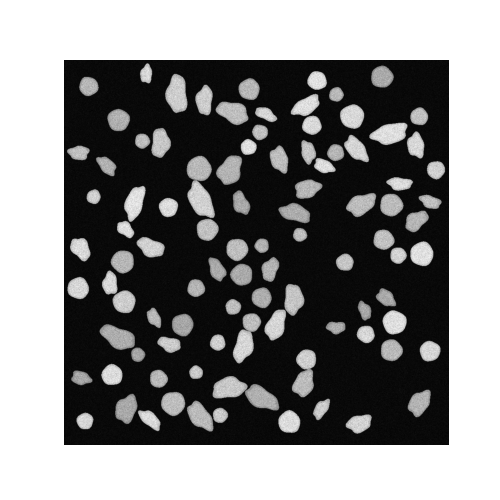

In [19]:
haadf_image = client[key]['image']['HAADF'].read()
metadata = dict(client[key]['image'].metadata)

plt.figure(figsize=(5, 5))
plt.imshow(haadf_image, cmap='gray')
plt.axis('off');

### Park the probe on a particle

Beam positions are fractional `(x, y)` coordinates in `[0, 1]`. The red marker shows where the next local diffraction measurement will be taken.

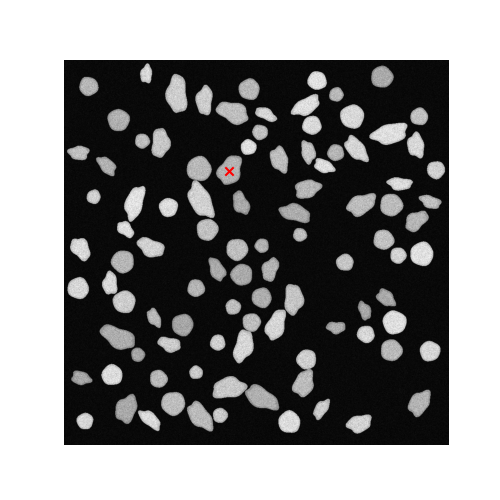

In [20]:
position = [440/1024,296/1024]
microscope.place_beam(position)

plt.figure(figsize=(5, 5))
plt.imshow(haadf_image, cmap='gray')
plt.scatter(position[0]*haadf_image.shape[1], position[1]*haadf_image.shape[0], color='red', marker='x')
plt.axis('off');

### Acquire a local diffraction pattern

A beam parked on a particle produces an abTEM diffraction pattern. A beam parked on the substrate produces the vacuum direct beam. Both acquisitions are saved through the same camera and Tiled path.

In [21]:
key = microscope.acquire_camera_image()
key

DevFailed: DevFailed[
    DevError[
        desc = RuntimeError: abTEM is required for diffraction simulation. Install it with `uv sync --extra diffraction`.
        origin = Traceback (most recent call last):
              File "C:\Users\gduscher\Documents\Github\asyncroscopy\asyncroscopy\instruments\electron_microscope\digital_twin_diffraction.py", line 295, in _simulate_diffraction_from_atoms
                import abtem
            ModuleNotFoundError: No module named 'abtem'

            The above exception was the direct cause of the following exception:

            Traceback (most recent call last):
              File "C:\Users\gduscher\Documents\Github\asyncroscopy\.venv\Lib\site-packages\tango\server.py", line 1790, in wrapped_command_method
                return get_worker().execute(cmd_method, *args, **kwargs)
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
              File "C:\Users\gduscher\Documents\Github\asyncroscopy\.venv\Lib\site-packages\

In [15]:
image = client[key]['image'].read()
metadata = dict(client[key]['image'].metadata)

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap='gray')
plt.axis('off')
plt.colorbar()

AttributeError: 'Container' object has no attribute 'read'

## Worked example: characterize particles from HAADF

Before choosing diffraction positions, extract useful structure from a fresh `1024 × 1024` HAADF overview. The worked example below:

1. segments all particles without OpenCV;
2. measures rotation-invariant size and shape statistics;
3. maps each statistic back onto the overview;
4. provides features that can guide later sampling decisions.

Diffraction is the expensive measurement, so this overview is the information used to decide where to spend the acquisition budget. The later adaptive exercise is inspired by local diffraction-pattern similarity and clustering ideas in [this paper](https://academic.oup.com/mam/article/32/3/ozag044/8701498).

### Acquire a calibrated `1024 × 1024` overview

The twin has a fixed `500 nm` field of view and saves the pixel size with every HAADF acquisition. Read that calibration from metadata instead of hard-coding it.

In [ ]:
scan.imsize = 1024
scan.dwell_time = 1e-6

overview_key = microscope.acquire_scanned_image(['HAADF'])
overview_node = client[overview_key]['image']['HAADF']
overview = np.asarray(overview_node.read(), dtype=np.float32)
overview_metadata = dict(overview_node.metadata)

fov_nm = float(overview_metadata.get('fov_nm', 500.0))
pixel_size_nm = float(overview_metadata.get('pixel_size_nm', fov_nm / overview.shape[0]))

print(f'key: {overview_key}')
print(f'image shape: {overview.shape}')
print(f'pixel size: {pixel_size_nm:.3f} nm / pixel')

In [ ]:
overview_norm = overview - np.nanmin(overview)
if np.nanmax(overview_norm) > 0:
    overview_norm = overview_norm / np.nanmax(overview_norm)

plt.figure(figsize=(6, 6))
plt.imshow(overview_norm, cmap='gray')
plt.title('Fresh HAADF overview')
plt.axis('off');

### Step 1: segment the overview

The example uses Otsu thresholding implemented with NumPy, followed by light cleanup with `scipy.ndimage`. No OpenCV is required.

As you inspect the result, ask: does the threshold preserve the full particle boundary? Would the same cleanup work if two particles touched?

In [ ]:
from scipy import ndimage
import pandas as pd
from matplotlib import colors

smoothed = ndimage.gaussian_filter(overview_norm, sigma=0.8)
hist, bin_edges = np.histogram(smoothed.ravel(), bins=256, range=(0.0, 1.0))
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
weight_bg = np.cumsum(hist)
weight_fg = hist.sum() - weight_bg
sum_bg = np.cumsum(hist * bin_centers)
sum_fg = np.sum(hist * bin_centers) - sum_bg
valid = (weight_bg > 0) & (weight_fg > 0)
between_class_variance = np.zeros_like(bin_centers)
between_class_variance[valid] = weight_bg[valid] * weight_fg[valid] * (sum_bg[valid] / weight_bg[valid] - sum_fg[valid] / weight_fg[valid]) ** 2
otsu_value = float(bin_centers[int(np.argmax(between_class_variance))])

foreground = smoothed >= otsu_value
foreground = ndimage.binary_opening(foreground, structure=np.ones((2, 2), dtype=bool))
labels, label_count = ndimage.label(foreground, structure=np.ones((3, 3), dtype=bool))

print(f'Otsu threshold: {otsu_value:.3f}')
print(f'raw connected components: {label_count}')

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(overview_norm, cmap='gray')
axes[0].set_title('HAADF overview')
axes[0].axis('off')

axes[1].imshow(foreground, cmap='gray')
axes[1].set_title('Thresholded mask')
axes[1].axis('off')

axes[2].imshow(labels, cmap='tab20', interpolation='nearest')
axes[2].set_title('Connected labels')
axes[2].axis('off')
plt.tight_layout()

### Step 2: compute rotation-invariant particle statistics

Each connected label receives size, center, and shape measurements. Rotation-invariant descriptors are useful because oval particles can point in any in-plane direction.

The table includes:

- area in pixels and `nm²`;
- equivalent radius and center of mass;
- `rmin` and `rmax`, measured from the center to the boundary;
- `rmax / rmin`, a simple orientation-independent irregularity score;
- covariance aspect ratio;
- circularity and radial coefficient of variation.

In [ ]:
min_area_px = max(12, int(0.00002 * overview.size))
centroids_yx = ndimage.center_of_mass(np.ones_like(labels, dtype=np.float32), labels, range(1, label_count + 1))
particle_rows = []
filtered_labels = np.zeros_like(labels, dtype=np.int32)
next_label = 1

for label_id, centroid_yx in zip(range(1, label_count + 1), centroids_yx):
    mask = labels == label_id
    area_px = int(np.count_nonzero(mask))
    if area_px < min_area_px or not np.all(np.isfinite(centroid_yx)):
        continue

    cy, cx = centroid_yx
    boundary = mask & ~ndimage.binary_erosion(mask, structure=np.ones((3, 3), dtype=bool), border_value=0)
    boundary_yx = np.column_stack(np.nonzero(boundary)).astype(np.float32)
    if len(boundary_yx) == 0:
        continue

    boundary_xy = boundary_yx[:, ::-1]
    boundary_dist_px = np.sqrt((boundary_xy[:, 0] - cx) ** 2 + (boundary_xy[:, 1] - cy) ** 2)
    rmin_px = float(np.min(boundary_dist_px))
    rmax_px = float(np.max(boundary_dist_px))

    yx = np.column_stack(np.nonzero(mask)).astype(np.float32)
    xy = yx[:, ::-1]
    centered = xy - np.array([[cx, cy]], dtype=np.float32)
    cov = np.cov(centered, rowvar=False) if len(centered) > 2 else np.eye(2)
    eigvals = np.sort(np.linalg.eigvalsh(cov))
    aspect_ratio = float(np.sqrt(eigvals[-1] / max(eigvals[0], 1e-9)))

    padded = np.pad(mask.astype(np.int8), 1)
    perimeter_px = float(np.sum(np.abs(np.diff(padded, axis=0))) + np.sum(np.abs(np.diff(padded, axis=1))))
    circularity = float(4 * np.pi * area_px / max(perimeter_px ** 2, 1e-9))
    radial_cv = float(np.std(boundary_dist_px) / max(np.mean(boundary_dist_px), 1e-9))

    filtered_labels[mask] = next_label
    particle_rows.append({
        'label': next_label,
        'area_px': area_px,
        'area_nm2': area_px * pixel_size_nm ** 2,
        'com_x_px': float(cx),
        'com_y_px': float(cy),
        'equivalent_radius_nm': float(np.sqrt(area_px / np.pi) * pixel_size_nm),
        'rmin_nm': rmin_px * pixel_size_nm,
        'rmax_nm': rmax_px * pixel_size_nm,
        'rmax_over_rmin': rmax_px / max(rmin_px, 1e-9),
        'radial_cv': radial_cv,
        'aspect_ratio_cov': aspect_ratio,
        'circularity': circularity,
    })
    next_label += 1

particle_stats = pd.DataFrame(particle_rows).sort_values('area_px', ascending=False).reset_index(drop=True)
particle_stats.head(12)

In [ ]:
stat_panels = [
    {
        'key': 'area_nm2',
        'title': 'Particle area',
        'ylabel': 'area (nm$^2$)',
        'xkey': 'equivalent_radius_nm',
        'xlabel': 'equivalent radius (nm)',
        'cmap': 'viridis',
    },
    {
        'key': 'circularity',
        'title': 'Circularity',
        'ylabel': 'circularity',
        'xkey': 'area_nm2',
        'xlabel': 'area (nm$^2$)',
        'cmap': 'plasma',
    },
    {
        'key': 'aspect_ratio_cov',
        'title': 'Covariance aspect ratio',
        'ylabel': 'aspect ratio',
        'xkey': 'area_nm2',
        'xlabel': 'area (nm$^2$)',
        'cmap': 'cividis',
    },
    {
        'key': 'radial_cv',
        'title': 'Radial boundary variation',
        'ylabel': 'radial CV',
        'xkey': 'area_nm2',
        'xlabel': 'area (nm$^2$)',
        'cmap': 'magma',
    },
]

fig, axes = plt.subplots(2, len(stat_panels), figsize=(18, 8), constrained_layout=True)
particle_labels = particle_stats['label'].to_numpy(dtype=int)

for column, panel in enumerate(stat_panels):
    values = particle_stats[panel['key']].to_numpy(dtype=float)
    value_by_label = np.full(int(filtered_labels.max()) + 1, np.nan, dtype=float)
    value_by_label[particle_labels] = values
    statistic_image = np.ma.masked_where(filtered_labels == 0, value_by_label[filtered_labels])

    vmin, vmax = float(np.nanmin(values)), float(np.nanmax(values))
    if np.isclose(vmin, vmax):
        vmin, vmax = vmin - 0.5, vmax + 0.5
    norm = colors.Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.colormaps[panel['cmap']].copy()
    cmap.set_bad('black')

    image_ax = axes[0, column]
    image = image_ax.imshow(statistic_image, cmap=cmap, norm=norm, interpolation='nearest')
    image_ax.set_title(panel['title'])
    image_ax.axis('off')
    fig.colorbar(image, ax=image_ax, fraction=0.046, pad=0.03, label=panel['ylabel'])

    scatter_ax = axes[1, column]
    scatter_ax.scatter(
        particle_stats[panel['xkey']],
        values,
        c=values,
        cmap=cmap,
        norm=norm,
        s=38,
        alpha=0.85,
        edgecolors='white',
        linewidths=0.3,
    )
    scatter_ax.set_xlabel(panel['xlabel'])
    scatter_ax.set_ylabel(panel['ylabel'])
    scatter_ax.set_title(f"{panel['title']} trend")
    scatter_ax.grid(alpha=0.2)

fig.suptitle(f'{len(particle_stats)} particles: spatial statistics and size trends', fontsize=14)


## Worked example: recover one local lattice parameter

The digital twin has two deliberately different lattice profiles:

- **Round particles:** center value `a₀ ~ N(4.078 Å, 0.015 Å)`, smoothly contracting to `0.75 a₀` at the boundary.
- **Oval particles:** center value `a₀ ~ N(4.678 Å, 0.015 Å)`, smoothly expanding to `1.25 a₀` at the boundary.

All particles are FCC and viewed along the `<100>` zone-axis family. The first allowed reflection is therefore `{200}`. The next cell works through direct-beam extraction, Richardson–Lucy deconvolution, radial integration, peak finding, and conversion from the `{200}` angle to `a`.

### Analyze one crystalline diffraction pattern

The example selects the largest segmented particle and parks the beam near its center. Follow each intermediate plot before using the compact function in the exercises.

In [ ]:
# Acquire a diffraction pattern and read its angular pixel size from metadata.
# Use the largest segmented particle and begin near its center.
target_particle = particle_stats.iloc[0]
beam_position = [
    float(target_particle['com_x_px'] / overview.shape[1]),
    float(target_particle['com_y_px'] / overview.shape[0]),
]

microscope.place_beam(beam_position)

diffraction_key = microscope.acquire_camera_image()
diffraction_node = client[diffraction_key]['image']
diffraction_pattern = np.asarray(diffraction_node.read(), dtype=np.float64)
diffraction_metadata = dict(diffraction_node.metadata)
pixel_size_mrad = float(diffraction_metadata['pixel_size_mrad'])


# Threshold the central disk to isolate the zero beam.
yy, xx = np.indices(diffraction_pattern.shape, dtype=float)
image_cy = (diffraction_pattern.shape[0] - 1) / 2
image_cx = (diffraction_pattern.shape[1] - 1) / 2
radius_from_image_center = np.hypot(xx - image_cx, yy - image_cy)
central_roi = radius_from_image_center < 0.08 * min(diffraction_pattern.shape)
zero_beam_threshold = 0.5 * float(diffraction_pattern[central_roi].max())
zero_beam_candidates = central_roi & (diffraction_pattern >= zero_beam_threshold)

# Keep only the connected bright region that contains the diffraction center.
candidate_labels, _ = ndimage.label(zero_beam_candidates)
center_label = candidate_labels[int(round(image_cy)), int(round(image_cx))]
zero_beam_mask = ndimage.binary_fill_holes(candidate_labels == center_label)

# Refine the diffraction center using the intensity-weighted zero beam.
zero_beam_weights = np.where(zero_beam_mask, diffraction_pattern, 0.0)
beam_cy = float(np.sum(yy * zero_beam_weights) / np.sum(zero_beam_weights))
beam_cx = float(np.sum(xx * zero_beam_weights) / np.sum(zero_beam_weights))
radius_px = np.hypot(xx - beam_cx, yy - beam_cy)
zero_beam_radius_px = float(np.percentile(radius_px[zero_beam_mask], 99))


# Richardson-Lucy deconvolution uses the measured zero beam as the point-spread function.
# Its nonnegative updates avoid the strong inner ringing produced by a Wiener inverse.
from scipy import constants, signal

beam_y, beam_x = np.nonzero(zero_beam_mask)
padding = 2
point_spread_function = zero_beam_weights[
    max(0, beam_y.min() - padding):beam_y.max() + padding + 1,
    max(0, beam_x.min() - padding):beam_x.max() + padding + 1,
]
point_spread_function /= np.sum(point_spread_function)
reflected_psf = point_spread_function[::-1, ::-1]
deconvolved = np.full_like(diffraction_pattern, max(float(diffraction_pattern.mean()), 1e-6))

for _ in range(15):
    blurred = signal.fftconvolve(deconvolved, point_spread_function, mode='same')
    relative_blur = diffraction_pattern / np.maximum(blurred, 1e-8)
    deconvolved *= signal.fftconvolve(relative_blur, reflected_psf, mode='same')
    deconvolved = np.clip(deconvolved, 0.0, None)

deconvolved[radius_px <= 1.05 * zero_beam_radius_px] = 0.0


# Radially sum the deconvolved pattern around the refined beam center.
radial_bin = np.floor(radius_px).astype(int)
radial_sum = np.bincount(radial_bin.ravel(), weights=deconvolved.ravel())
radial_sum = ndimage.gaussian_filter1d(radial_sum, sigma=1.5)
radial_angle_mrad = np.arange(len(radial_sum)) * pixel_size_mrad


# Find the first Bragg peak immediately outside the zero-beam disk.
search_start = int(np.ceil(1.05 * zero_beam_radius_px))
search_stop = min(len(radial_sum), int(np.ceil(50.0 / pixel_size_mrad)))
search_profile = radial_sum[search_start:search_stop]
peak_indices, _ = signal.find_peaks(
    search_profile,
    prominence=0.03 * float(search_profile.max()),
    distance=max(1, int(round(2.0 / pixel_size_mrad))),
)
if len(peak_indices) == 0:
    raise RuntimeError('No Bragg peak found. Try a beam position farther from the particle edge.')

first_peak_bin = int(search_start + peak_indices[0])

# Quadratic interpolation gives a sub-pixel estimate of the radial peak position.
left, center, right = radial_sum[first_peak_bin - 1:first_peak_bin + 2]
denominator = left - 2 * center + right
peak_offset = 0.5 * (left - right) / denominator if denominator != 0 else 0.0
first_peak_radius_px = first_peak_bin + float(np.clip(peak_offset, -0.5, 0.5))
first_peak_mrad = first_peak_radius_px * pixel_size_mrad

# In the FCC <100> zone-axis family, the first allowed reflection is {200}, so a = 2 d200.
accelerating_voltage_v = 200_000.0
electron_wavelength_m = constants.h / np.sqrt(
    2 * constants.m_e * constants.e * accelerating_voltage_v
    * (1 + constants.e * accelerating_voltage_v / (2 * constants.m_e * constants.c ** 2))
)
electron_wavelength_angstrom = electron_wavelength_m * 1e10
scattering_angle_rad = first_peak_mrad * 1e-3
d200_angstrom = electron_wavelength_angstrom / (2 * np.sin(scattering_angle_rad / 2))
lattice_parameter_angstrom = 2 * d200_angstrom

print(f'diffraction key: {diffraction_key}')
print(f'angular pixel size: {pixel_size_mrad:.4f} mrad / pixel')
print(f'first {{200}} peak: {first_peak_mrad:.3f} mrad')
print(f'estimated FCC lattice parameter: {lattice_parameter_angstrom:.3f} Å')


# Plot the acquisition, extracted zero beam, deconvolution, and radial peak.
fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)

axes[0, 0].imshow(np.log1p(1000 * diffraction_pattern), cmap='magma')
axes[0, 0].set_title('Acquired diffraction pattern (log scale)')
axes[0, 0].axis('off')

axes[0, 1].imshow(zero_beam_weights, cmap='gray')
axes[0, 1].set_title(f'Extracted zero beam ({zero_beam_radius_px * pixel_size_mrad:.2f} mrad radius)')
axes[0, 1].axis('off')

axes[1, 0].imshow(np.log1p(deconvolved), cmap='magma')
axes[1, 0].set_title('Richardson-Lucy-deconvolved pattern')
axes[1, 0].axis('off')

radial_sum_normalized = radial_sum / max(float(radial_sum.max()), 1e-12)
axes[1, 1].plot(radial_angle_mrad, radial_sum_normalized, color='black')
axes[1, 1].axvspan(0, radial_angle_mrad[search_start], color='0.9', label='direct beam excluded')
axes[1, 1].axvline(first_peak_mrad, color='tab:red', linestyle='--', label='{200} peak')
axes[1, 1].scatter([first_peak_mrad], [np.interp(first_peak_mrad, radial_angle_mrad, radial_sum_normalized)], color='tab:red')
axes[1, 1].set_xlim(0, min(50, radial_angle_mrad[-1]))
axes[1, 1].set_xlabel('scattering angle (mrad)')
axes[1, 1].set_ylabel('normalized radial sum')
axes[1, 1].set_title(f'Radial sum: a = {lattice_parameter_angstrom:.3f} Å')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.2)


In [ ]:
def get_lattice_param(diff_pattern, pixel_size):
    """Return the FCC <100> lattice parameter in Å; pixel_size is mrad/pixel."""
    from scipy import constants, ndimage, signal

    pattern = np.asarray(diff_pattern, dtype=float)
    yy, xx = np.indices(pattern.shape, dtype=float)
    image_cy = (pattern.shape[0] - 1) / 2
    image_cx = (pattern.shape[1] - 1) / 2
    radius = np.hypot(xx - image_cx, yy - image_cy)

    central_roi = radius < 0.08 * min(pattern.shape)
    candidates = central_roi & (pattern >= 0.5 * pattern[central_roi].max())
    labels, _ = ndimage.label(candidates)
    center_label = labels[int(round(image_cy)), int(round(image_cx))]
    zero_beam_mask = ndimage.binary_fill_holes(labels == center_label)
    zero_beam = np.where(zero_beam_mask, pattern, 0.0)

    beam_cy = np.sum(yy * zero_beam) / np.sum(zero_beam)
    beam_cx = np.sum(xx * zero_beam) / np.sum(zero_beam)
    radius = np.hypot(xx - beam_cx, yy - beam_cy)
    zero_beam_radius = np.percentile(radius[zero_beam_mask], 99)

    beam_y, beam_x = np.nonzero(zero_beam_mask)
    psf = zero_beam[
        max(0, beam_y.min() - 2):beam_y.max() + 3,
        max(0, beam_x.min() - 2):beam_x.max() + 3,
    ]
    psf /= psf.sum()
    estimate = np.full_like(pattern, max(float(pattern.mean()), 1e-6))
    for _ in range(15):
        blurred = signal.fftconvolve(estimate, psf, mode='same')
        estimate *= signal.fftconvolve(
            pattern / np.maximum(blurred, 1e-8), psf[::-1, ::-1], mode='same'
        )
        estimate = np.clip(estimate, 0.0, None)

    estimate[radius <= 1.05 * zero_beam_radius] = 0.0
    radial_bin = np.floor(radius).astype(int)
    radial_sum = np.bincount(radial_bin.ravel(), weights=estimate.ravel())
    radial_sum = ndimage.gaussian_filter1d(radial_sum, sigma=1.5)

    search_start = int(np.ceil(1.05 * zero_beam_radius))
    search_stop = min(len(radial_sum), int(np.ceil(50.0 / pixel_size)))
    profile = radial_sum[search_start:search_stop]
    peaks, _ = signal.find_peaks(
        profile,
        prominence=0.03 * profile.max(),
        distance=max(1, int(round(2.0 / pixel_size))),
    )
    if len(peaks) == 0:
        raise ValueError('No crystalline {200} peak found at this beam position.')

    peak_bin = search_start + int(peaks[0])
    left, center, right = radial_sum[peak_bin - 1:peak_bin + 2]
    denominator = left - 2 * center + right
    offset = 0.5 * (left - right) / denominator if denominator != 0 else 0.0
    scattering_angle = (peak_bin + np.clip(offset, -0.5, 0.5)) * pixel_size * 1e-3

    voltage = 200_000.0
    wavelength = constants.h / np.sqrt(
        2 * constants.m_e * constants.e * voltage
        * (1 + constants.e * voltage / (2 * constants.m_e * constants.c**2))
    )
    d200 = wavelength * 1e10 / (2 * np.sin(scattering_angle / 2))
    return float(2 * d200)


## Hackathon exercises

### Exercise 1: compare center-to-edge lattice profiles

Use the particle statistics to choose one round-looking particle and one oval-looking particle. For each particle, sample a radial path from its center toward the edge and call `get_lattice_param` at every crystalline position.

Questions to investigate:

- Can you recover contraction in the round particle and expansion in the oval particle?
- Where does the estimator stop finding a reliable `{200}` peak, and what changes in the pattern there?
- How many measurements are needed to distinguish the two profiles reliably?
- Which HAADF shape statistic best predicts the sign of the lattice gradient?

In [ ]:
# Your work: choose one round-like and one oval-like particle,
# then construct beam positions that run from each center through its boundary.


In [ ]:
# Your work: acquire each radial profile and plot lattice parameter
# against distance from the particle center.


### Exercise 2: build an adaptive lattice-parameter map

Now reconstruct a two-dimensional lattice map from a small number of diffraction measurements. Treat unmeasured positions as unknown and let disagreement between sparse reconstructions suggest the next beam position.

Start with a modest acquisition budget, watch the reconstruction evolve, and decide when another measurement is no longer worth its cost. Pay attention to locations where a scalar lattice parameter becomes difficult or impossible to assign.

In [ ]:
# 1. Pick a particle and look at the region you will map.
# Use particle_stats to choose particles with different shape descriptors.
particle_number = 0
padding = 4

target_label = int(particle_stats.iloc[particle_number]['label'])
particle_mask = filtered_labels == target_label
particle_rows, particle_columns = np.nonzero(particle_mask)

row_slice = slice(
    max(0, int(particle_rows.min()) - padding),
    min(overview.shape[0], int(particle_rows.max()) + padding + 1),
)
column_slice = slice(
    max(0, int(particle_columns.min()) - padding),
    min(overview.shape[1], int(particle_columns.max()) + padding + 1),
)
region_mask = particle_mask[row_slice, column_slice]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(overview_norm, cmap='gray')
axes[0].contour(particle_mask, levels=[0.5], colors='cyan', linewidths=1)
axes[0].set_title(f'Particle {target_label} in the overview')
axes[1].imshow(overview_norm[row_slice, column_slice], cmap='gray')
axes[1].contour(region_mask, levels=[0.5], colors='cyan', linewidths=1)
axes[1].set_title(f'Mapping region: {region_mask.sum()} possible points')
for ax in axes:
    ax.axis('off')
plt.tight_layout()

In [ ]:
# 2. A compact reconstruction helper.
# It combines several DCT reconstructions. Their disagreement, plus distance
# from existing measurements, becomes the uncertainty score.
from scipy.fft import dctn, idctn


def reconstruct_scalar_map(values, measured, region, bounds=(3.0, 6.0), iterations=30):
    lower, upper = bounds
    normalized = np.zeros_like(values, dtype=float)
    normalized[measured] = np.clip(
        (values[measured] - lower) / (upper - lower), 0.0, 1.0
    )

    _, nearest = ndimage.distance_transform_edt(~measured, return_indices=True)
    starting_map = normalized[nearest[0], nearest[1]]
    candidates = []

    for sparsity in [0.04, 0.08, 0.16]:
        estimate = starting_map.copy()
        keep_count = max(1, int(sparsity * estimate.size))

        for _ in range(iterations):
            coefficients = dctn(estimate, norm='ortho')
            threshold = np.partition(
                np.abs(coefficients).ravel(), -keep_count
            )[-keep_count]
            estimate = idctn(
                coefficients * (np.abs(coefficients) >= threshold), norm='ortho'
            )
            estimate[measured] = normalized[measured]
            estimate = np.clip(estimate, 0.0, 1.0)

        candidates.append(estimate)

    candidates = np.asarray(candidates)
    reconstruction = lower + (upper - lower) * candidates.mean(axis=0)
    disagreement = candidates.std(axis=0)
    distance = ndimage.distance_transform_edt(~measured)

    disagreement /= max(float(disagreement[region].max()), 1e-12)
    distance /= max(float(distance[region].max()), 1e-12)
    uncertainty = 0.7 * disagreement + 0.3 * distance

    reconstruction[~region] = np.nan
    uncertainty[~region] = np.nan
    uncertainty[measured] = 0.0
    return reconstruction, uncertainty

In [ ]:
# 3. Measure, reconstruct, look, and repeat.
# Start with a small budget. Watching each update is more useful than waiting
# for a large run to finish.
from IPython.display import clear_output

measurement_budget = 20
lattice_bounds = (3.0, 6.0)
measured_values = np.zeros(region_mask.shape, dtype=float)
measured_mask = np.zeros(region_mask.shape, dtype=bool)
uncertainty_history = []

# Begin safely inside the particle. Later positions come from uncertainty.
distance_from_edge = ndimage.distance_transform_edt(region_mask)
next_row, next_column = np.unravel_index(
    np.argmax(distance_from_edge), region_mask.shape
)

for step in range(measurement_budget):
    full_row = row_slice.start + next_row
    full_column = column_slice.start + next_column
    beam_position = [
        full_column / (overview.shape[1] - 1),
        full_row / (overview.shape[0] - 1),
    ]

    # This is the same acquisition pattern used in the worked example.
    microscope.place_beam(beam_position)
    diffraction_key = microscope.acquire_camera_image()
    diffraction_node = client[diffraction_key]['image']
    diffraction_pattern = np.asarray(diffraction_node.read(), dtype=np.float64)
    diffraction_metadata = dict(diffraction_node.metadata)
    pixel_size_mrad = float(diffraction_metadata['pixel_size_mrad'])
    lattice_parameter = get_lattice_param(diffraction_pattern, pixel_size_mrad)

    measured_values[next_row, next_column] = lattice_parameter
    measured_mask[next_row, next_column] = True
    reconstruction, uncertainty = reconstruct_scalar_map(
        measured_values, measured_mask, region_mask, lattice_bounds
    )
    uncertainty_history.append(float(np.nanmax(uncertainty)))
    next_row, next_column = np.unravel_index(
        np.nanargmax(uncertainty), uncertainty.shape
    )

    clear_output(wait=True)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    measured_display = np.where(measured_mask, measured_values, np.nan)
    axes[0].imshow(
        measured_display, cmap='viridis', vmin=lattice_bounds[0], vmax=lattice_bounds[1]
    )
    axes[0].set_title(f'Measured: {measured_mask.sum()} points')
    axes[1].imshow(
        reconstruction, cmap='viridis', vmin=lattice_bounds[0], vmax=lattice_bounds[1]
    )
    axes[1].set_title('Current reconstruction')
    axes[2].imshow(uncertainty, cmap='magma', vmin=0, vmax=1)
    axes[2].scatter(next_column, next_row, marker='x', s=100, color='cyan')
    axes[2].set_title('Uncertainty and next point')
    for ax in axes:
        ax.axis('off')
    plt.show()

In [ ]:
# What did the sampler learn?
# A falling curve means the reconstruction models are becoming less uncertain.
plt.figure(figsize=(7, 3))
plt.plot(np.arange(1, len(uncertainty_history) + 1), uncertainty_history, marker='o')
plt.xlabel('Measurements acquired')
plt.ylabel('Maximum uncertainty')
plt.title('Did each new measurement reduce uncertainty?')
plt.grid(alpha=0.3)
plt.show()

# Your turn:
# - Compare a round-looking particle with an oval-looking particle.
# - Change the measurement budget and the three sparsity values.
# - Stop the loop early when the uncertainty curve becomes nearly flat.
# - Hard: map the crystalline parts of the whole overview with fewer than 500 measurements.